# 03. Insights and business decision
1. Survival: how long do customers last?  2. Cohort retention.  3. Three statistical tests.
4. Revenue at risk, who is worth contacting, and how sensitive the answer is to assumptions.

**Input:** `sales_clean.csv`, `test_scored.csv`. **Output:** `targeting_list.csv`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, mannwhitneyu

import churn_utils  # noqa: F401  (silences a harmless pandas warning)

PROC = Path("data/processed")
sales = pd.read_csv(PROC / "sales_clean.csv", parse_dates=["invoice_date"])
feat = pd.read_csv(PROC / "test_scored.csv", index_col="customer_id")

## 1. Survival analysis
duration = days from first to last order; event = 1 if no order in the last 90 days of data
(otherwise the customer is still active, so the lifetime is "censored").
Cox covariates are known at the first order only, so the model is not circular.

Median lifetime (days): 427.0
30     0.757
90     0.717
180    0.654
365    0.538
Name: All customers, dtype: float64


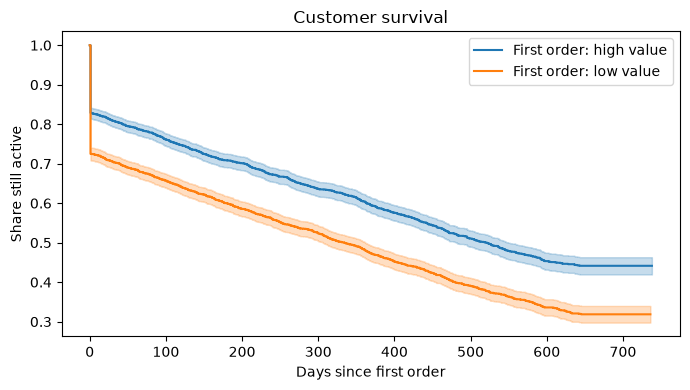

                       hazard_ratio      p
covariate                                 
log_first_order_value         0.808  0.000
log_first_order_items         0.955  0.144
is_uk                         0.912  0.167
hazard_ratio > 1 = leaves sooner, < 1 = stays longer


In [2]:
inv = (sales.groupby(["customer_id", "invoice"])
            .agg(date=("invoice_date", "min"), value=("revenue", "sum"),
                 items=("quantity", "sum"), country=("country", "first"))
            .reset_index().sort_values(["customer_id", "date"]))
first, last_date = inv.groupby("customer_id").first(), inv.groupby("customer_id")["date"].max()
surv = pd.DataFrame({
    "duration": (last_date - first["date"]).dt.days.clip(lower=1),
    "event": (last_date < sales["invoice_date"].max() - pd.Timedelta(days=90)).astype(int),
    "log_first_order_value": np.log1p(first["value"]),
    "log_first_order_items": np.log1p(first["items"]),
    "is_uk": (first["country"] == "United Kingdom").astype(int)})

try:
    from lifelines import CoxPHFitter, KaplanMeierFitter
    kmf = KaplanMeierFitter().fit(surv["duration"], surv["event"], label="All customers")
    print("Median lifetime (days):", kmf.median_survival_time_)
    print(kmf.survival_function_at_times([30, 90, 180, 365]).round(3))

    fig, ax = plt.subplots(figsize=(7, 4))
    big = surv["log_first_order_value"] >= surv["log_first_order_value"].median()
    for mask, name in [(big, "First order: high value"), (~big, "First order: low value")]:
        KaplanMeierFitter().fit(surv.loc[mask, "duration"], surv.loc[mask, "event"],
                                label=name).plot_survival_function(ax=ax)
    ax.set(xlabel="Days since first order", ylabel="Share still active", title="Customer survival")
    plt.tight_layout()
    plt.show()

    cph = CoxPHFitter(penalizer=0.01).fit(surv, duration_col="duration", event_col="event")
    print(cph.summary[["exp(coef)", "p"]].rename(columns={"exp(coef)": "hazard_ratio"}).round(3))
    print("hazard_ratio > 1 = leaves sooner, < 1 = stays longer")
except ImportError:
    print("pip install lifelines to run the survival analysis")

## 2. Cohort retention
Cohort = month of first purchase. The first month of data is excluded (it holds every
pre-existing customer) and so is a partial final month.

Average retention (weighted by cohort size):
1     21.0%
2     21.5%
3     21.1%
4     19.4%
5     18.6%
6     18.4%
7     18.6%
8     16.4%
9     15.0%
10    13.5%
11    14.0%
12    18.4%


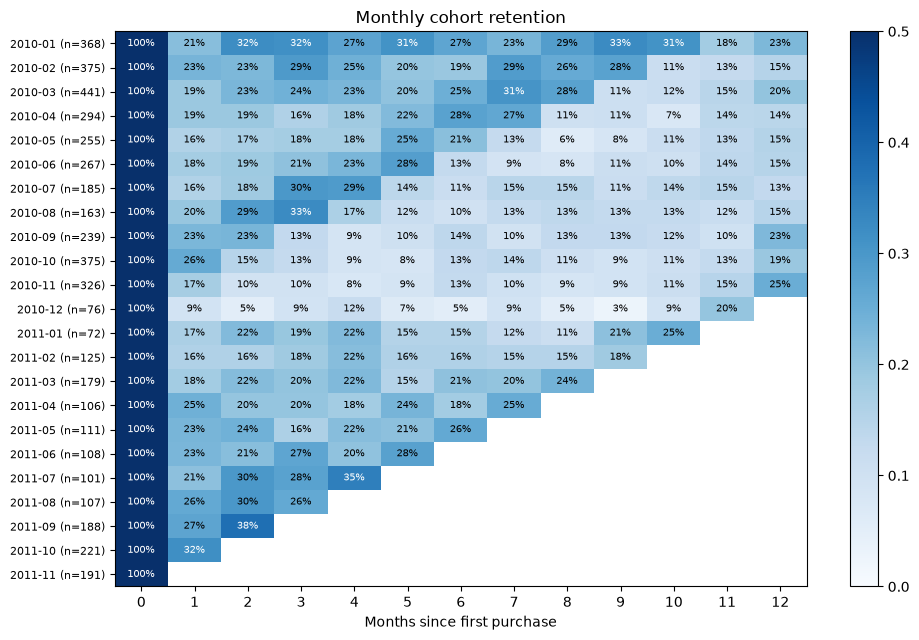

In [3]:
sales["m"] = sales["invoice_date"].dt.year * 12 + sales["invoice_date"].dt.month
end = sales["invoice_date"].max()
last_m = end.year * 12 + end.month - (end.day < end.days_in_month)
act = sales.loc[sales["m"] <= last_m, ["customer_id", "m"]].drop_duplicates()
act["cohort"] = act.groupby("customer_id")["m"].transform("min")
act = act[act["cohort"] > sales["m"].min()].assign(k=lambda d: d["m"] - d["cohort"])

sizes = act[act["k"] == 0].groupby("cohort")["customer_id"].nunique()
counts = act.groupby(["cohort", "k"])["customer_id"].nunique()
K = 12
ret = pd.DataFrame({k: [counts.get((c, k), 0) / s if c + k <= last_m else np.nan
                        for c, s in sizes.items()] for k in range(K + 1)},
                   index=[f"{(c - 1) // 12}-{(c - 1) % 12 + 1:02d} (n={s})" for c, s in sizes.items()])
avg = {k: sum(counts.get((c, k), 0) for c in sizes.index if c + k <= last_m)
          / sizes[[c + k <= last_m for c in sizes.index]].sum() for k in range(1, K + 1)}
print("Average retention (weighted by cohort size):")
print(pd.Series(avg).map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(ret.values.astype(float), cmap="Blues", vmin=0, vmax=0.5, aspect="auto")
ax.set(xticks=range(K + 1), yticks=range(len(ret)), xlabel="Months since first purchase",
       title="Monthly cohort retention")
ax.set_yticklabels(ret.index, fontsize=8)
for i, j in np.argwhere(~np.isnan(ret.values.astype(float))):
    ax.text(j, i, f"{ret.iat[i, j]:.0%}", ha="center", va="center", fontsize=7,
            color="white" if ret.iat[i, j] > 0.3 else "black")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 3. Statistical tests (with effect sizes)
With thousands of customers almost any difference is "significant", so we report an effect size
too. We run 3 tests, so the Bonferroni threshold is 0.05 / 3.

In [4]:
rows = []
def chi_square(name, flag):
    tab = pd.crosstab(flag, feat["churn"])
    chi2, p, _, _ = chi2_contingency(tab)
    a, b = feat.loc[flag, "churn"], feat.loc[~flag, "churn"]
    diff, se = a.mean() - b.mean(), np.sqrt(a.var() / len(a) + b.var() / len(b))
    rows.append({"test": f"Chi-square: {name}", "churn rates": f"{a.mean():.1%} vs {b.mean():.1%}",
                 "difference (95% CI)": f"{diff:+.1%} ({diff - 1.96 * se:+.1%} to {diff + 1.96 * se:+.1%})",
                 "p": p, "effect size": f"Cramer's V = {np.sqrt(chi2 / len(feat)):.3f}"})

chi_square("one-time vs repeat buyers", feat["frequency"] == 1)
chi_square("returned items vs never", feat["return_lines"] > 0)
a, b = feat.loc[feat["churn"] == 1, "recency_days"], feat.loc[feat["churn"] == 0, "recency_days"]
u, p = mannwhitneyu(a, b)
rows.append({"test": "Mann-Whitney: recency, churned vs stayed", "churn rates": f"median {a.median():.0f} vs {b.median():.0f} days",
             "difference (95% CI)": "", "p": p, "effect size": f"P(churner higher) = {u / (len(a) * len(b)):.3f}"})
res = pd.DataFrame(rows)
res["significant"] = np.where(res["p"] < 0.05 / 3, "yes", "no")
res["p"] = res["p"].map("{:.1e}".format)
pd.set_option("display.width", 250, "display.max_colwidth", 80)
print(res.to_string(index=False))

                                    test           churn rates       difference (95% CI)        p               effect size significant
   Chi-square: one-time vs repeat buyers        79.6% vs 46.8% +32.8% (+30.2% to +35.3%) 1.4e-106        Cramer's V = 0.303         yes
     Chi-square: returned items vs never        41.7% vs 67.0% -25.4% (-28.0% to -22.7%)  4.0e-74        Cramer's V = 0.251         yes
Mann-Whitney: recency, churned vs stayed median 284 vs 65 days                           3.5e-232 P(churner higher) = 0.762         yes


## 4. Revenue at risk and who to contact
Benefit of contacting a customer = P(churn) x save rate x 90-day value x margin
minus the discount paid to everyone who buys, minus the contact cost.
**The assumptions below are placeholders: change them and state them in the README.**

Expected 90-day revenue 2,604,889 | revenue at risk 698,558
Already lapsed (> 180 days silent): 2,478 of 5,253 customers (47%), revenue at risk 324,657
                   strategy  contacted  net_benefit
           Contact everyone       2775    -166268.0
    Contact top 20% by risk        555       -648.0
Contact only if benefit > 0        211        267.0


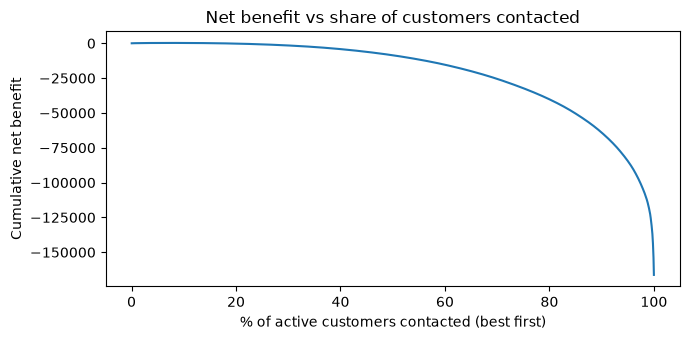

Saved targeting_list.csv with 211 customers


In [5]:
MARGIN, SAVE_RATE, DISCOUNT, CONTACT_COST, MAX_RECENCY = 0.30, 0.20, 0.10, 0.50, 180

df = feat.copy()
df["value_90d"] = df["monetary"] / df["tenure_days"].clip(lower=90) * 90   # avg spend per 90 days
df["revenue_at_risk"] = df["p_adj"] * df["value_90d"]
lapsed = df["recency_days"] > MAX_RECENCY            # silent too long: win-back, not retention
print(f"Expected 90-day revenue {df['value_90d'].sum():,.0f} | revenue at risk {df['revenue_at_risk'].sum():,.0f}")
print(f"Already lapsed (> {MAX_RECENCY} days silent): {lapsed.sum():,} of {len(df):,} customers "
      f"({lapsed.mean():.0%}), revenue at risk {df.loc[lapsed, 'revenue_at_risk'].sum():,.0f}")
df = df[~lapsed].copy()

def net_benefit(save, discount):
    p, v = df["p_adj"], df["value_90d"]
    # the discount is also paid to customers who would have stayed anyway (1 - p)
    return p * save * v * MARGIN - ((1 - p) + p * save) * discount * v - CONTACT_COST

df["benefit"] = net_benefit(SAVE_RATE, DISCOUNT)
top20 = df.nlargest(int(len(df) * 0.2), "p_adj")
print(pd.DataFrame({
    "strategy": ["Contact everyone", "Contact top 20% by risk", "Contact only if benefit > 0"],
    "contacted": [len(df), len(top20), (df["benefit"] > 0).sum()],
    "net_benefit": [df["benefit"].sum(), top20["benefit"].sum(),
                    df.loc[df["benefit"] > 0, "benefit"].sum()]}).round(0).to_string(index=False))

ranked = df["benefit"].sort_values(ascending=False).reset_index(drop=True)
ax = (ranked.cumsum().set_axis((ranked.index + 1) / len(ranked) * 100)
            .plot(figsize=(7, 3.5), title="Net benefit vs share of customers contacted"))
ax.set(xlabel="% of active customers contacted (best first)", ylabel="Cumulative net benefit")
plt.tight_layout()
plt.show()

(df[df["benefit"] > 0].sort_values("benefit", ascending=False)
   [["p_adj", "value_90d", "revenue_at_risk", "benefit", "recency_days", "frequency"]]
   .round(2).to_csv(PROC / "targeting_list.csv"))
print("Saved targeting_list.csv with", (df["benefit"] > 0).sum(), "customers")

### Sensitivity: how much do the conclusions depend on the assumptions?
Discount 0% means a reminder email or call with no price cut.

In [6]:
sens = []
for disc in (0.0, 0.05, 0.10):
    for save in (0.05, 0.10, 0.20, 0.30):
        b = net_benefit(save, disc)
        sens.append({"discount": f"{disc:.0%}", "save_rate": f"{save:.0%}", "contacted_if_smart": int((b > 0).sum()),
                     "net_if_smart": round(b[b > 0].sum()), "net_if_contact_everyone": round(b.sum())})
print(pd.DataFrame(sens).to_string(index=False))

discount save_rate  contacted_if_smart  net_if_smart  net_if_contact_everyone
      0%        5%                2440          4285                     4221
      0%       10%                2663          9846                     9830
      0%       20%                2757         21048                    21047
      0%       30%                2771         32264                    32264
      5%        5%                  23             7                   -86632
      5%       10%                 244           228                   -81958
      5%       20%                 772          2889                   -72611
      5%       30%                1111          7371                   -63263
     10%        5%                   0             0                  -177485
     10%       10%                  23             8                  -173746
     10%       20%                 211           267                  -166268
     10%       30%                 433          1326            